#  Hotel Booking Analysis

## Exploratory Data Analysis using Python

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

---

## Project Overview

This project analyzes hotel booking data for City Hotel and Resort Hotel.

The objective is to understand customer booking behavior, identify booking trends, analyze cancellation patterns, and generate business insights that can help improve hotel performance.

## Business Objective

The objective of this analysis is to examine hotel booking data and answer business-related questions such as:

- Which hotel type is preferred?
- What is the cancellation rate?
- Which months receive the highest bookings?
- Which meals are most preferred?
- How does the Average Daily Rate vary?
- What factors can help improve hotel revenue?

The insights can support better pricing strategies, marketing campaigns, and operational planning.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("Hotel Bookings.csv")

In [4]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-15


In [5]:
df.shape

(119390, 32)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [8]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

## Data Cleaning

In [9]:
# Check missing values
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [10]:
# Fill missing values
df["children"] = df["children"].fillna(0)

In [11]:
# Drop company column because most values are missing
df.drop(columns=["company"], inplace=True)

The company column contained a very large amount of missing values, so it was removed from analysis.

## Exploratory Data Analysis

In [12]:
# 1. Which hotel type is most preferred ?

hotel_counts = df['hotel'].value_counts().index[0]
print("Most Preferred hotel by guests is : ", hotel_counts)

Most Preferred hotel by guests is :  City Hotel


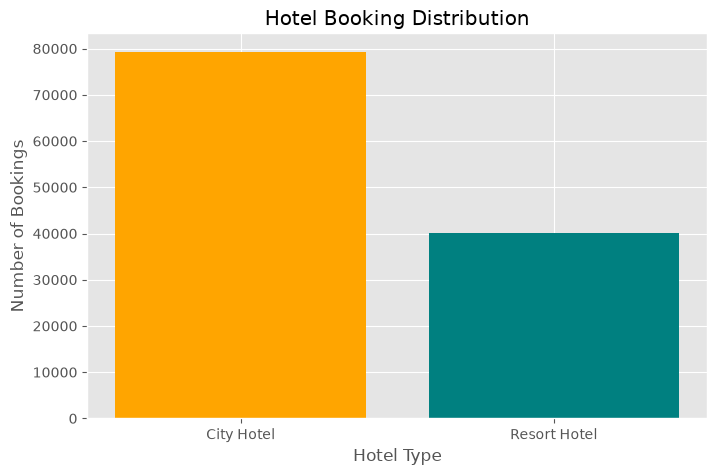

In [13]:
# Bar Chart 

hotel_counts = df['hotel'].value_counts()
plt.figure(figsize=(8,5))
plt.bar(hotel_counts.index, hotel_counts.values, color=['orange', 'teal'])
plt.title('Hotel Booking Distribution')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=0)

plt.show()

 **Insight :** City Hotel has more bookings than Resort Hotel, indication higher customer preferrence.

In [14]:
# Q.2 What is percentage of hotel booking cancellation ?

percentage_cancelled = df['is_canceled'].mean() * 100
print(f"Percentage of hotel booking cancellations: {percentage_cancelled:.2f}%")

Percentage of hotel booking cancellations: 37.04%


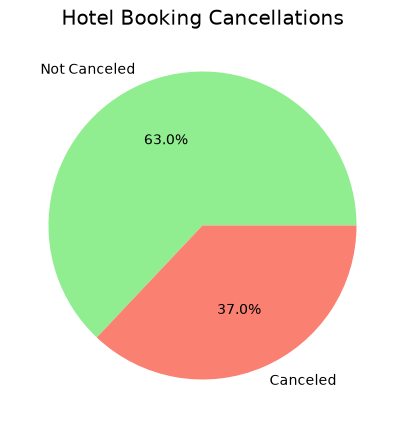

In [15]:
# Pie Chart

cancel_counts = df['is_canceled'].value_counts()
labels = ['Not Canceled', 'Canceled']
plt.figure(figsize=(5,5))
plt.pie(cancel_counts.values, labels=labels, autopct='%1.1f%%', colors=['lightgreen' , 'salmon'])
plt.title('Hotel Booking Cancellations')


plt.show()

**Insight:** Approximately 63% of bookings were successfully completed, while the 37% cancellation rate indicates room for improvement. Implementing measures to reduce cancellations could enhance customer retention, occupancy, and revenue.

In [16]:
# Q.3 Which type of meal is most preferred by guests ?

meal_counts = df['meal'].value_counts()
print("Most preferred meal is:", meal_counts.index[0])

Most preferred meal is: BB


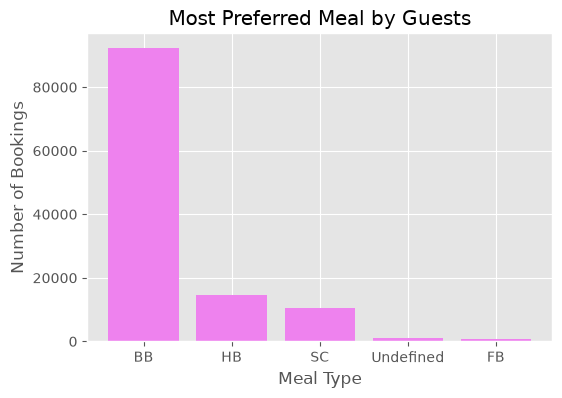

In [17]:
# Bar Chart 

plt.figure(figsize=(6,4))
plt.bar(meal_counts.index, meal_counts.values, color='violet')
plt.title('Most Preferred Meal by Guests')
plt.xlabel('Meal Type')
plt.ylabel('Number of Bookings')

plt.show()

**Insight:** BB was the most preferred meal plan among guests, indicating a strong preference for breakfast-inclusive bookings. Maintaining the quality of this meal plan and offering attractive breakfast packages could further enhance guest satisfaction and encourage repeat bookings.

In [18]:
# Q.4 Which year has the most bookings ?

year_counts = df['arrival_date_year'].value_counts().sort_index()
print("The year wth the most booking is :",year_counts.idxmax())

The year wth the most booking is : 2016


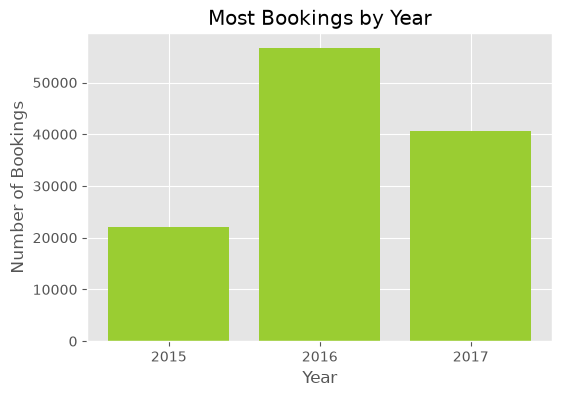

In [19]:
# Bar Chart 

plt.figure(figsize=(6,4))
plt.bar(year_counts.index.astype(str), year_counts.values, color='yellowgreen' )
plt.title('Most Bookings by Year')
plt.xlabel('Year')
plt.ylabel('Number of Bookings')

plt.show()

**Insight:** 2016 recorded the highest number of hotel bookings, indicating increased customer demand during that year. Analyzing the factors that contributed to this growth can help the hotel develop strategies to sustain and improve future booking performance.


In [20]:
# Q.5 Which month has the most bookings in each hotel type ?

most_booked_month= df['arrival_date_month'].value_counts().head(1).index[0]
print("The most booking month is :",most_booked_month)

hotel_counts = df[df['arrival_date_month'] == most_booked_month]['hotel'].value_counts()

print(f"\nTotal bookings in {most_booked_month} in each hotel is : ")
print(hotel_counts)

The most booking month is : August

Total bookings in August in each hotel is : 
hotel
City Hotel      8983
Resort Hotel    4894
Name: count, dtype: int64


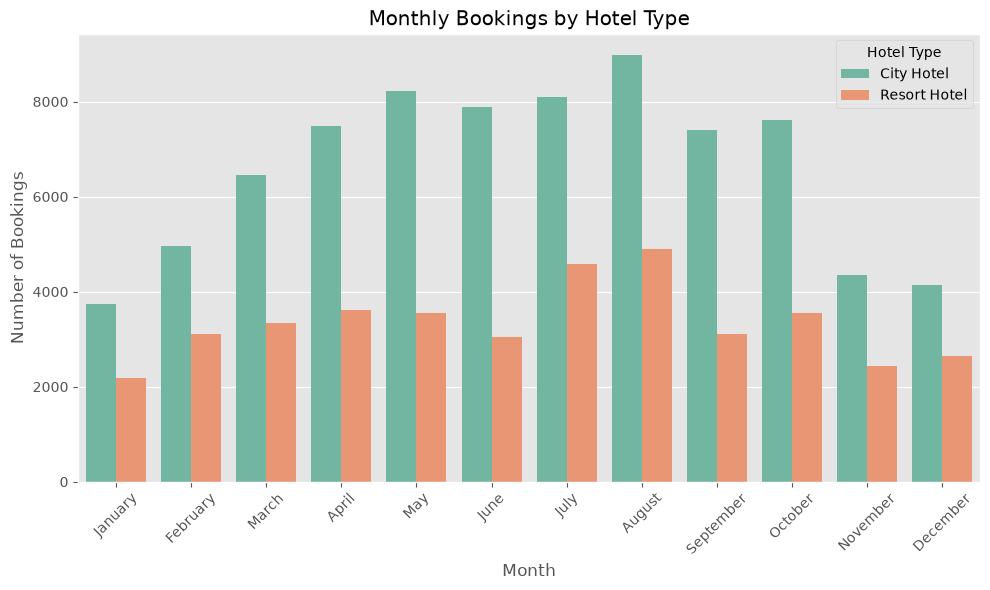

In [21]:
# Grouped bar chart

monthly_hotel_counts = df.groupby(['arrival_date_month', 'hotel']).size().reset_index(name='Bookings')

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_hotel_counts['arrival_date_month'] = pd.Categorical(monthly_hotel_counts['arrival_date_month'], categories=month_order, ordered=True)
monthly_hotel_counts = monthly_hotel_counts.sort_values('arrival_date_month')

plt.figure(figsize=(10,6))
sns.barplot(data=monthly_hotel_counts, x='arrival_date_month', y='Bookings', hue='hotel', palette='Set2')

plt.title('Monthly Bookings by Hotel Type')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Hotel Type')
plt.tight_layout()
plt.show()

**Insight:** August experienced the highest booking volume across both hotel types, highlighting it as the peak travel season.
Leveraging this trend through dynamic pricing, targeted promotions, and effective resource planning can further enhance occupancy, revenue, and overall business performance.


In [22]:
# Q.6 From which country most guests come ?

top_country = df['country'].value_counts().idxmax()
print("The country from which most guests come is:", top_country)

The country from which most guests come is: PRT


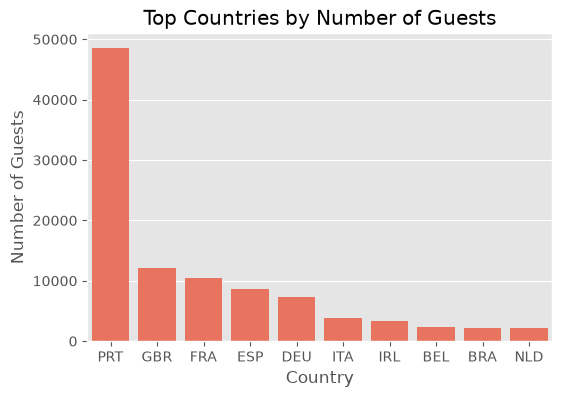

In [23]:
# Bar Chart

top_countries = df['country'].value_counts().head(10)

plt.figure(figsize=(6,4))
sns.barplot(x=top_countries.index, y=top_countries.values, color='tomato')

plt.title('Top Countries by Number of Guests')
plt.xlabel('Country')
plt.ylabel('Number of Guests')
plt.show()

**Insight:** The majority of guests came from **PRT**, highlighting it as a key source market for the hotel. Continuing to serve this market effectively while expanding promotional efforts to attract guests from other countries can help diversify the customer base and drive future growth.

In [24]:
# Q.7 Which distribution channel is most used in booking ?

most_used = df['distribution_channel'].value_counts().head(1).index[0]
print("Most used distribution channel is:", most_used)

Most used distribution channel is: TA/TO


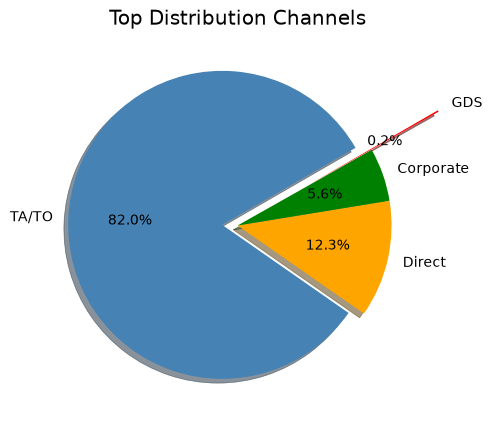

In [25]:
# Pie Chart

channel = df['distribution_channel'].value_counts().head(4)

explode_values = [0.1, 0, 0, 0.5]

plt.figure(figsize=(5,5))

plt.pie(
    channel.values,
    labels=channel.index,
    autopct='%0.1f%%',
    explode=explode_values,
    shadow=True,
    startangle=30,
    colors=['steelblue', 'orange', 'green', 'red']
)

plt.title("Top Distribution Channels")
plt.show()

**Insight:** TA/TO (Travel Agents and Tour Operators)** was the most frequently used distribution channel for hotel bookings, highlighting its importance in attracting guests. Strengthening partnerships with travel agencies while expanding other booking channels can help increase bookings and reach a broader customer base.

In [26]:
# Q.8 Which room type is most prefered by guests ?

preferred_room_type = df['reserved_room_type'].value_counts().head(1).index[0]
print("Most prefered room type by guests is:", preferred_room_type)

Most prefered room type by guests is: A


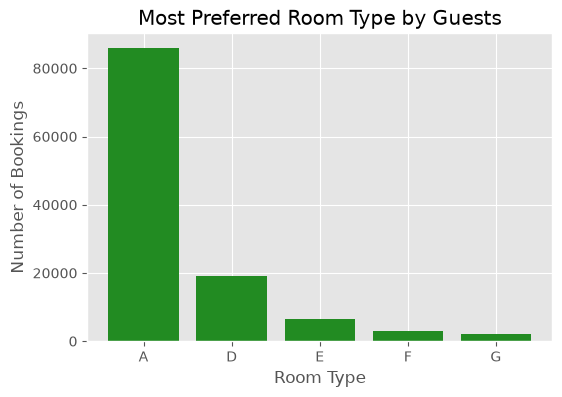

In [27]:
# Bar Chart 

room_type_counts = df['reserved_room_type'].value_counts().head(5)

plt.figure(figsize=(6,4))
plt.bar(room_type_counts.index, room_type_counts.values, color=['forestgreen'])
plt.title('Most Preferred Room Type by Guests')
plt.xlabel('Room Type')
plt.ylabel('Number of Bookings')

plt.show()

 **Insight:** Room Type A was the most preferred choice among guests, indicating higher demand for this room category. Maintaining its quality and availability while using this demand to guide room allocation and pricing strategies can help improve customer satisfaction and overall business performance.

In [28]:
# Q.9 Which room type is most assigned ?

assigned_room_type = df['assigned_room_type'].value_counts().idxmax()
print("Most assigned room type is:", assigned_room_type)

Most assigned room type is: A


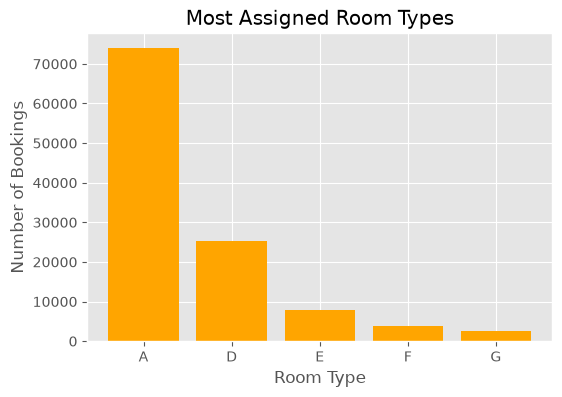

In [29]:
# Bar Chart 

assigned_room_counts = df['assigned_room_type'].value_counts().head(5)

plt.figure(figsize=(6,4))
plt.bar(assigned_room_counts.index, assigned_room_counts.values, color='orange')

plt.title('Most Assigned Room Types')
plt.xlabel('Room Type')
plt.ylabel('Number of Bookings')

plt.show()

**Insight:** Room Type A was the most frequently assigned room, indicating that it was the hotel's primary room category. Ensuring its availability and maintaining service quality can help improve operational efficiency and enhance the overall guest experience.

In [30]:
# Q.10 Top 5 agents in terms of most bookings ?

top_5_agents = df['agent'].value_counts().head(5)
print("Top 5 agent interms of most booking are : ", top_5_agents)

Top 5 agent interms of most booking are :  agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
Name: count, dtype: int64


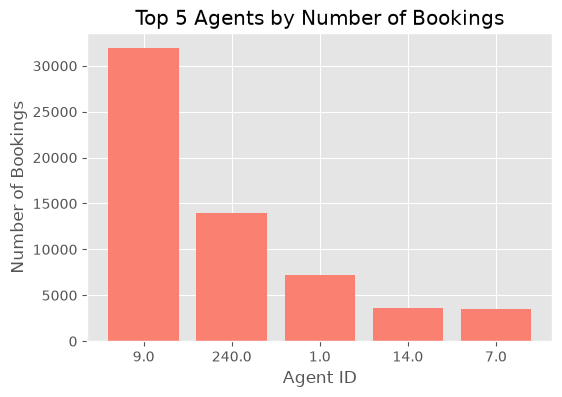

In [31]:
# Bar Chart

top_5_agents = df['agent'].value_counts().head(5)

plt.figure(figsize=(6,4))
plt.bar(top_5_agents.index.astype(str), top_5_agents.values, color='salmon')

plt.title('Top 5 Agents by Number of Bookings')
plt.xlabel('Agent ID')
plt.ylabel('Number of Bookings')

plt.show()

**Insight:** Agent 9 handled the highest number of hotel bookings, highlighting its significant contribution to the hotel's booking volume. Strengthening relationships with high-performing agents while expanding collaborations with other agents could help increase bookings and broaden the hotel's market reach.


In [32]:
# Q.11 What is the percentage of repeated guests ?

Repeated_guests = (df['is_repeated_guest'].sum() / len(df)) * 100
print(f"Repeated Guest Percentage: {Repeated_guests:.2f}%")

Repeated Guest Percentage: 3.19%


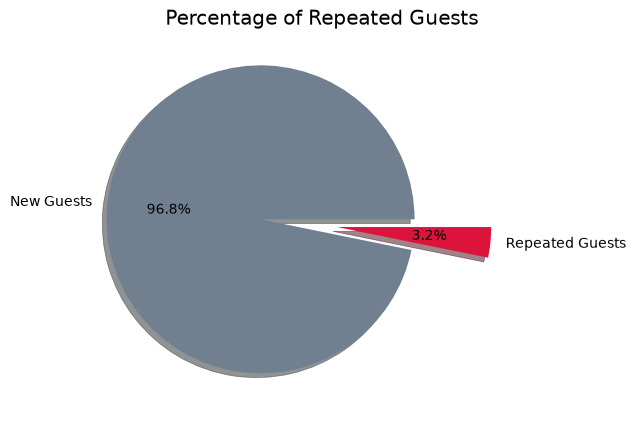

In [33]:
# Pie Chart

Repeated_guests = df['is_repeated_guest'].value_counts()

plt.figure(figsize=(5,5))
plt.pie(Repeated_guests, labels=['New Guests', 'Repeated Guests'], autopct='%0.1f%%', colors=['slategrey', 'crimson'], 
        explode=[0.4, 0.1],shadow=True)
plt.title("Percentage of Repeated Guests")

plt.show()

**Insight:** Only 3.19% of the total guests were repeat customers, while the majority were first-time visitors. This indicates that the hotels primarily rely on attracting new guests for bookings. Maintaining high customer satisfaction and delivering a positive guest experience can encourage repeat visits whenever guests return to the destination or require hotel accommodations in the future, helping build a stronger customer base over time.

In [34]:
# Q.12 Which customer type has the most booking ?

most_booking_customer = df['customer_type'].value_counts().head(1).index[0]
print("Customer type with the most bookings:", most_booking_customer)

Customer type with the most bookings: Transient


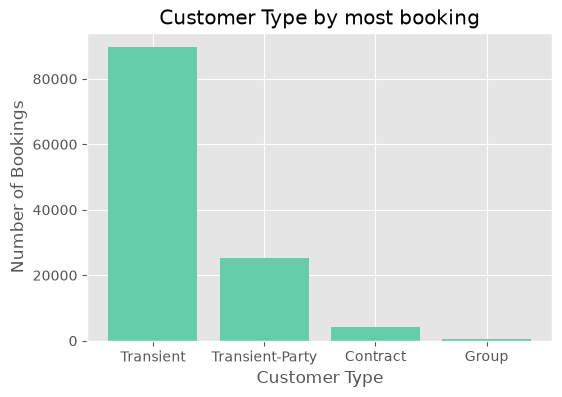

In [35]:
# Bar Graph

most_booking_customer = df['customer_type'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(most_booking_customer.index,most_booking_customer.values,color=['mediumaquamarine'])
plt.title('Customer Type by most booking')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')

plt.show()

**Insight:** Transient customers accounted for the highest number of hotel bookings, indicating that individual travelers and independent bookings contribute the largest share of the hotel's business. This suggests that maintaining excellent customer service, competitive pricing, and effective online booking channels for transient guests can help sustain booking volume and support overall revenue growth.


In [36]:
# Q.13 Which Market Segment has the most booking ?

most_booking_market_segment = df['market_segment'].value_counts().idxmax()
print("Most booking type of market segment : ", most_booking_market_segment)

Most booking type of market segment :  Online TA


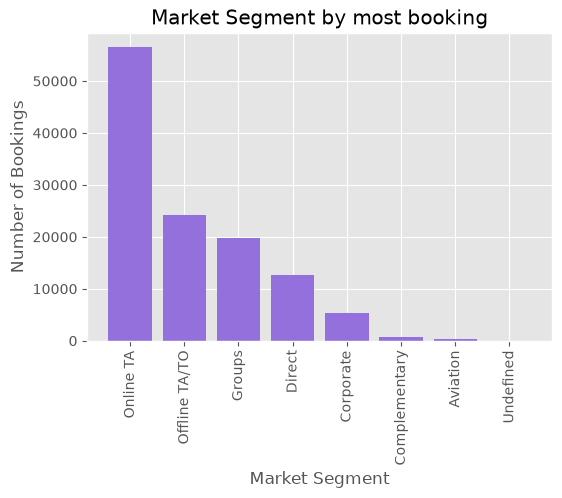

In [37]:
# Bar Graph

most_booking_market_segment = df['market_segment'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(most_booking_market_segment.index,most_booking_market_segment.values,color=['mediumpurple'])
plt.title('Market Segment by most booking')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=90)
plt.show()

**Insight:** Online Travel Agents (Online TA) generated the highest number of hotel bookings, highlighting their significant role in attracting guests. This indicates that online booking platforms are a major source of business for the hotels. Strengthening partnerships with online travel agencies while maintaining an attractive online presence can help increase booking volume and support consistent revenue growth.

In [38]:
# Q.14 Which deposit type is most preferred ?

preferred_deposit_type = df['deposit_type'].value_counts().head(1).index[0]
print("Most preferred deposit type is : ", preferred_deposit_type)

Most preferred deposit type is :  No Deposit


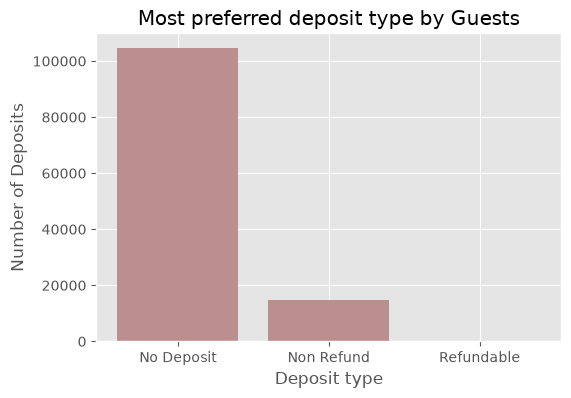

In [39]:
# Bar Graph

preferred_deposit_type = df['deposit_type'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(preferred_deposit_type.index,preferred_deposit_type.values,color=['rosybrown'])
plt.title('Most preferred deposit type by Guests')
plt.xlabel('Deposit type')
plt.ylabel('Number of Deposits')
plt.show()

**Insight:** No Deposit was the most preferred deposit type among guests, indicating that most customers preferred making reservations without paying an advance deposit. This suggests that flexible booking policies may encourage more reservations. However, the hotel should continue monitoring booking and cancellation patterns to ensure that offering flexible deposit options supports both customer convenience and business profitability.

In [40]:
# Q.15 How long people stay in the hotel ?

df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

Stay_time = df['total_stay'].value_counts().head(1)
print("Most common length of stay: ", Stay_time)

Most common length of stay:  total_stay
2    27643
Name: count, dtype: int64


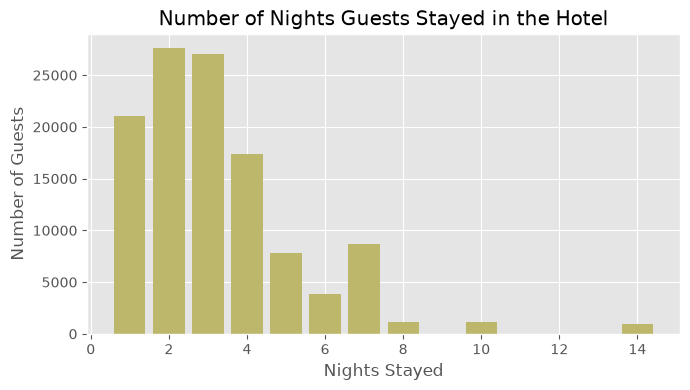

In [41]:
# Bar Graph

Stay_time = df['total_stay'].value_counts().head(10).sort_index()

plt.figure(figsize=(7,4))
plt.bar(Stay_time.index, Stay_time.values, color='darkkhaki')
plt.title('Number of Nights Guests Stayed in the Hotel')
plt.xlabel('Nights Stayed')
plt.ylabel('Number of Guests')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** Most guests stayed at the hotel for 2 nights, indicating a preference for short-duration stays. This suggests that the hotels primarily cater to travelers seeking brief leisure or business trips. Offering attractive short-stay packages, personalized services, and a seamless guest experience can help maximize occupancy, encourage positive reviews, and increase the likelihood of future bookings.


In [42]:
# Q.16 Which hotel makes most revenue ? 

df['total_stay'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']
df['estimated_revenue'] = df['adr'] * df['total_stay']

hotel_revenue = df.groupby('hotel')['estimated_revenue'].sum().sort_values(ascending=False)

Revenue_count = hotel_revenue.index[0]
Top_revenue = hotel_revenue.values[0]

print("The hotel which makes most revenue is:", Revenue_count)
print("Total revenue generated by this hotel is:", round(Top_revenue, 2))

The hotel which makes most revenue is: City Hotel
Total revenue generated by this hotel is: 25279469.96


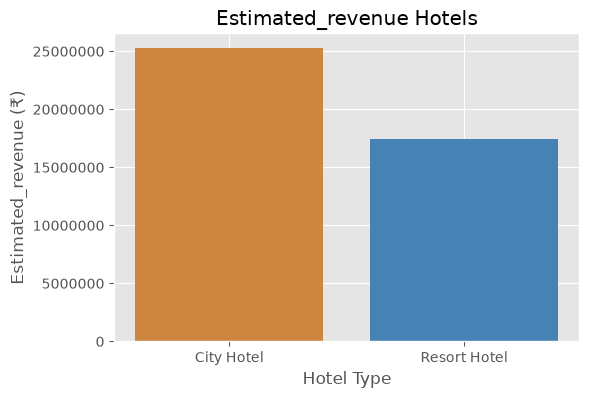

In [43]:
# Bar Chart 

plt.figure(figsize=(6,4))
plt.bar(hotel_revenue.index, hotel_revenue.values, color=['peru','steelblue'])
plt.title('Estimated_revenue Hotels')
plt.xlabel('Hotel Type')
plt.ylabel('Estimated_revenue (₹)')
plt.ticklabel_format(style='plain', axis='y')

plt.show()

**Insight:** City Hotel generated the highest total revenue, indicating its strong contribution to the hotel's overall financial performance. This suggests that its higher booking volume and room occupancy played a significant role in revenue generation. Maintaining service quality, optimizing room pricing, and implementing effective revenue management strategies can help sustain profitability while continuing to attract guests.

In [44]:
# Q.17 Which hotel has the longer waiting time ?

average_waiting = df.groupby('hotel')['days_in_waiting_list'].mean().sort_values(ascending=False)

print("Hotel with the highest average waiting time:", average_waiting.index[0])
print("Average waiting time:", round(average_waiting.iloc[0], 2), "days")

Hotel with the highest average waiting time: City Hotel
Average waiting time: 3.23 days


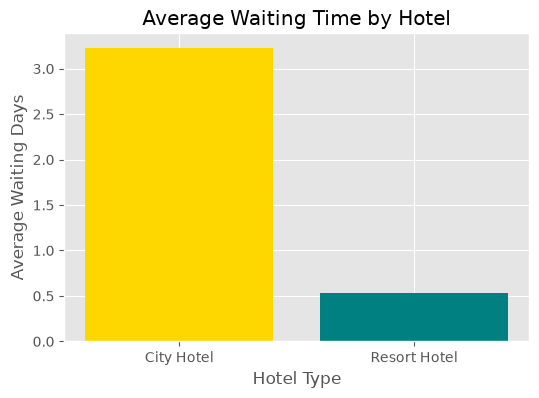

In [45]:
# Bar Chart

Longer_Waiting_time = df.groupby('hotel')['days_in_waiting_list'].mean()
plt.figure(figsize=(6,4))
plt.bar(Longer_Waiting_time.index, Longer_Waiting_time.values, color=['gold','teal'])
plt.title('Average Waiting Time by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Average Waiting Days')

plt.show()

**Insight:** City Hotel recorded the highest average waiting time, indicating that guests generally waited longer for bookings compared to Resort Hotel. This may reflect higher demand for City Hotel during certain periods. Monitoring room availability, optimizing reservation management, and improving capacity planning can help reduce waiting times while maintaining guest satisfaction and operational efficiency.

In [46]:
# Q.18 Hotel with most repeated guests.

Repeated_guests = df[df['is_repeated_guest'] == 1]['hotel'].value_counts()
print("Number of Repeated Guests in each hotel:\n", Repeated_guests)

print("Hotel with most repeated guests is:", Repeated_guests.index[0])

Number of Repeated Guests in each hotel:
 hotel
City Hotel      2032
Resort Hotel    1778
Name: count, dtype: int64
Hotel with most repeated guests is: City Hotel


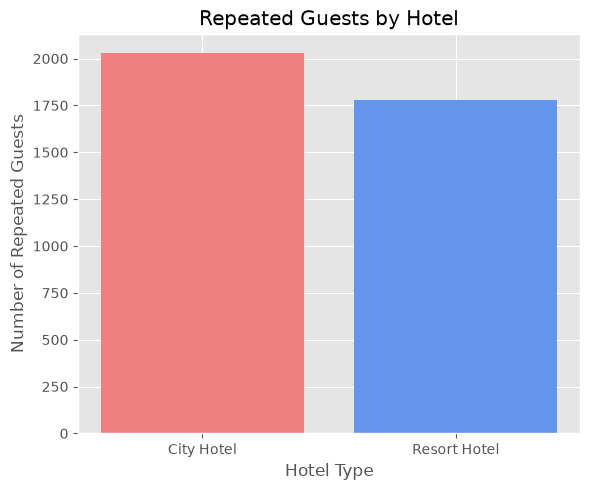

In [47]:
# Bar Plot

plt.figure(figsize=(6,5))
plt.bar(Repeated_guests.index, Repeated_guests.values, color=['lightcoral', 'cornflowerblue'])
plt.title('Repeated Guests by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Repeated Guests')
plt.tight_layout()
plt.show()

**Insight:** City Hotel recorded the highest number of repeated guests, indicating that it attracts more returning customers than Resort Hotel. This suggests that City Hotel has been successful in encouraging guests to return for future stays. Continuing to deliver high-quality service and a positive guest experience can help strengthen customer satisfaction, encourage repeat visits, and support long-term business growth.

In [48]:
# Q.19 What is the adr across different months ?

Adr_across_months = df.groupby('arrival_date_month', observed=True)['adr'].mean()
print("The ADR across different months is :\n", Adr_across_months) 


The ADR across different months is :
 arrival_date_month
April        100.380790
August       140.111523
December      81.076776
February      73.582276
January       70.361241
July         126.788013
June         116.672192
March         80.679646
May          108.695516
November      73.794962
October       87.908879
September    105.049657
Name: adr, dtype: float64


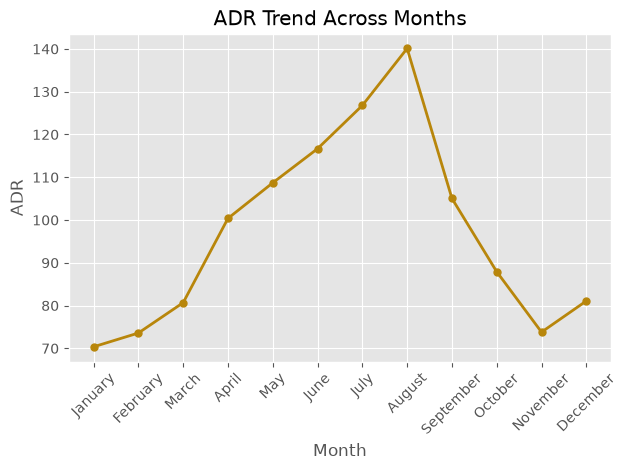

In [49]:
# Line Char

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

df['arrival_date_month'] = pd.Categorical(
    df['arrival_date_month'],
    categories=month_order,
    ordered=True
)

Adr_across_months = df.groupby('arrival_date_month', observed=True)['adr'].mean()
plt.plot(Adr_across_months.index, Adr_across_months.values,color='darkgoldenrod', 
         linestyle='solid',linewidth=2,marker='o', markersize=5)

plt.title('ADR Trend Across Months')
plt.xlabel('Month')
plt.ylabel('ADR')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Insight:** August recorded the highest Average Daily Rate (ADR), indicating that room prices were highest during this month. This suggests a period of strong demand, allowing the hotel to charge higher room rates. Optimizing pricing strategies during high-demand months while maintaining service quality can help maximize revenue and improve overall business performance.

In [50]:
# Q.20 Which distribution channel has highest adr ? 

adr_by_channel = df.groupby('distribution_channel')['adr'].mean().sort_values(ascending=False)

print("Distribution channel with the highest ADR:", adr_by_channel.index[0])
print("Average ADR:", round(adr_by_channel.iloc[0], 2))

Distribution channel with the highest ADR: GDS
Average ADR: 120.55


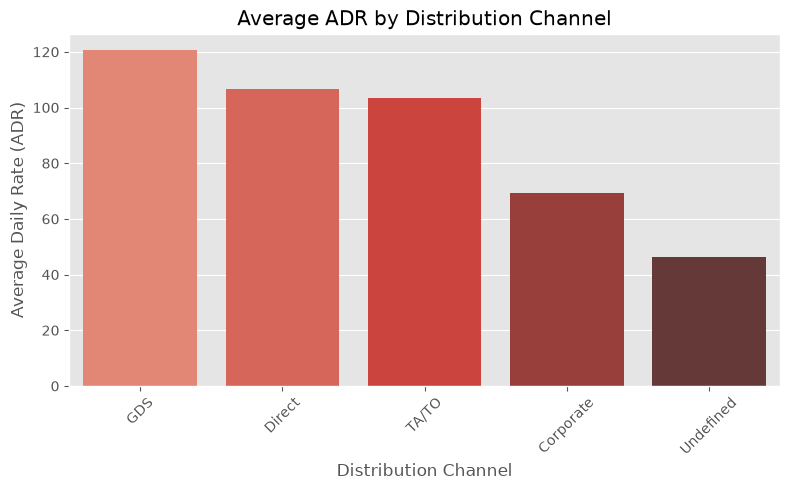

In [51]:
# Bar graph

adr_by_channel = df.groupby('distribution_channel')['adr'].mean().reset_index().sort_values(by='adr', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(data=adr_by_channel, x='distribution_channel', y='adr', hue='distribution_channel', palette='Reds_d', legend=False)
plt.title('Average ADR by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** The Global Distribution System (GDS) distribution channel recorded the highest Average Daily Rate (ADR), indicating that bookings made through this channel generated higher room rates compared to other distribution channels. This suggests that GDS attracts bookings with higher revenue potential. Maintaining strong partnerships with GDS providers and ensuring competitive pricing can help maximize revenue while expanding the hotel's reach to a broader customer base.

**Q.21 What do you suggest the client to achieve Business Object ?**

The objective of this analysis is to gather and analyze booking data for 'City Hotel' and 'Resort Hotel' to help the client make informed decisions that improve business performance, enhance guest satisfaction, and increase overall profitability.

**Guest Preference for Hotel Type:**
The analysis shows that City Hotel has more bookings than Resort Hotel. The client should further analyze the factors contributing to this difference and identify opportunities to improve bookings for the Resort Hotel.

**Peak Season Management:**
According to the analysis, August recorded the highest number of bookings, indicating a peak season. The client can optimize room pricing and allocate resources efficiently during high-demand periods to maximize revenue while maintaining service quality.

**Off-Season Strategies:**
The client should implement strategies to attract more guests during low-demand periods. Special offers, promotional campaigns, personalized family packages, and corporate discounts can help increase bookings during the off-season.

**Reduce Booking Cancellations:**
The analysis indicates a considerable number of booking cancellations. The client should identify the key reasons behind these cancellations and implement measures to reduce them, helping minimize revenue loss and improve occupancy.

**Improve Customer Satisfaction:**
The percentage of repeated guests is relatively low. The client should focus on maintaining high customer satisfaction and delivering a positive guest experience to encourage repeat visits whenever guests return to the destination. Regularly collecting and analyzing guest feedback can also help identify areas for continuous improvement.

**Maintain Revenue Growth:**
The hotel generating the highest estimated revenue should continue to receive investments in service quality and operational efficiency to sustain its performance. At the same time, improvement strategies should be implemented for the other hotel to strengthen its revenue contribution and support overall business growth.

**Reduce Waiting Time:**
One of the hotels has a higher average waiting time, which may affect the guest experience. The client should identify the factors contributing to longer waiting times and improve reservation and operational processes to reduce delays and enhance customer satisfaction.

**Optimize Average Daily Rate (ADR):**
The client should continuously monitor ADR across different months and distribution channels. By identifying the channels that generate higher room rates, the client can focus on strengthening those partnerships while adjusting pricing strategies during lower-ADR periods to maximize revenue.


**Q.22 Conclusion.**

The analysis of hotel booking data for **City Hotel** and **Resort Hotel** provides valuable insights into guest preferences, booking patterns, pricing trends, and overall business performance.

The findings show that **City Hotel** received more bookings and generated the highest estimated revenue, while **Resort Hotel** has opportunities to improve its booking performance. **August** recorded the highest number of bookings and the highest Average Daily Rate (ADR), indicating a peak season where effective pricing and resource planning can help maximize revenue.

The analysis also revealed a considerable number of booking cancellations, highlighting the need to identify their causes and implement strategies to reduce revenue loss. Although the percentage of repeated guests is relatively low, maintaining high customer satisfaction and delivering a positive guest experience can encourage repeat visits whenever guests return to the destination.

Most guests preferred **short-duration stays**, indicating that the hotels primarily serve travelers seeking brief visits. Enhancing the guest experience and offering attractive short-stay packages can help maximize occupancy and encourage future bookings.

Additionally, monitoring ADR across different distribution channels and months can support better pricing decisions, while focusing on high-performing market segments and distribution channels can improve marketing effectiveness and increase revenue.

Overall, this analysis provides a comprehensive understanding of hotel booking patterns, guest behavior, pricing trends, and business performance. The insights and recommendations presented can support improvements in customer satisfaction, operational efficiency, revenue optimization, and the overall performance of both City Hotel and Resort Hotel.
